# Data Visualization – Customer Personality Analysis

## Business problem
A food delivery and retail company wants to understand its customers so it can plan marketing better.
We want to answer two questions:
1. **How much will a customer spend?** (regression)
2. **Is the customer High-Value or Regular?** (classification)

This notebook explores the data **before** training any model.

**Dataset source (Kaggle):** https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis

| Column used | Meaning |
|---|---|
| Year_Birth → age | Customer's age |
| Education | Education level |
| Marital_Status | Married, Single, Together, Divorced, Widow |
| Income | Yearly household income |
| Kidhome / Teenhome | Number of small children / teenagers at home |
| Recency | Days since the last purchase |
| NumWebVisitsMonth | Visits to the company website last month |
| Mnt... (6 columns) | Money spent on each product type in 2 years → added together as **total_spending** |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# The CSV is one folder up. If you move the notebook, it also checks the current folder.
data_path = Path("../marketing_campaign.csv")
if not data_path.exists():
    data_path = Path("marketing_campaign.csv")

df = pd.read_csv(data_path)
print("Shape:", df.shape)
df.head()

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## Basic information

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

`df.info()` shows 29 columns. Most are numbers; Education, Marital_Status and Dt_Customer are text.

In [3]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nRepeated customers (same data, different ID):", df.drop("ID", axis=1).duplicated().sum())

Missing values:
Income    24
dtype: int64

Repeated customers (same data, different ID): 182


Income has **24 missing values**, and **182 customers appear twice** with a different ID. Both are fixed in preprocessing.

## Finding wrong values (outliers) before cleaning

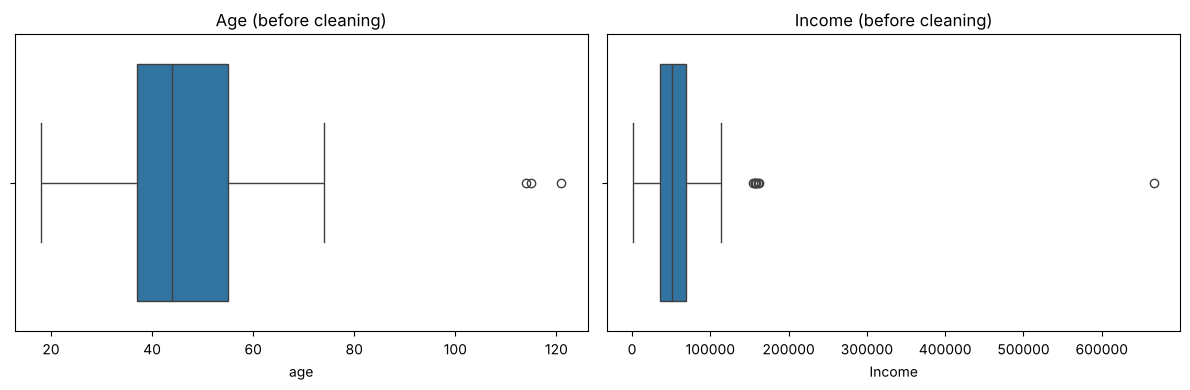

Customers older than 90: 3 -> [114, 115, 121]
Highest income: 666666.0


In [4]:
df["age"] = 2014 - df["Year_Birth"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["age"], ax=axes[0])
axes[0].set_title("Age (before cleaning)")
sns.boxplot(x=df["Income"], ax=axes[1])
axes[1].set_title("Income (before cleaning)")
plt.tight_layout()
plt.show()

print("Customers older than 90:", (df["age"] > 90).sum(), "->", sorted(df.loc[df["age"] > 90, "age"].tolist()))
print("Highest income:", df["Income"].max())

**What it explains:** Three customers are 114–121 years old and one income is 666,666. These are data entry mistakes, so we remove them.

## Strange marital status values

In [5]:
print(df["Marital_Status"].value_counts())

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


"Alone", "Absurd" and "YOLO" are not real categories (7 customers). We treat them as "Single".

## Data Preprocessing
1. **Remove repeated customers** – same data entered twice with a new ID.
2. **Create the target** `total_spending` = money spent on wine, fruit, meat, fish, sweets and gold.
3. **Create age** from year of birth (data collected in 2014).
4. **Keep the useful columns** and give them short names.
5. **Remove rows with missing income** (only 24 rows).
6. **Remove impossible values** – age above 90 and one income of 666,666.
7. **Fix strange marital status values** ("Alone", "Absurd", "YOLO" → "Single").

In [6]:
df = df.drop("ID", axis=1).drop_duplicates()
df = df.drop(columns=["age"])

spending_columns = ["MntWines", "MntFruits", "MntMeatProducts",
                    "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["total_spending"] = df[spending_columns].sum(axis=1)
df["age"] = 2014 - df["Year_Birth"]

df = df[["age", "Education", "Marital_Status", "Income", "Kidhome",
         "Teenhome", "Recency", "NumWebVisitsMonth", "total_spending"]]
df.columns = ["age", "education", "marital_status", "income", "kids",
              "teens", "recency", "web_visits", "total_spending"]

df = df.dropna()
df = df[(df["age"] <= 90) & (df["income"] <= 200000)]
df["marital_status"] = df["marital_status"].replace(
    {"Alone": "Single", "Absurd": "Single", "YOLO": "Single"}
)

print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (2030, 9)


,age,education,marital_status,income,kids,teens,recency,web_visits,total_spending
0,57,Graduation,Single,58138.0,0,0,58,7,1617
1,60,Graduation,Single,46344.0,1,1,38,5,27
2,49,Graduation,Together,71613.0,0,0,26,4,776
3,30,Graduation,Together,26646.0,1,0,26,6,53
4,33,PhD,Married,58293.0,1,0,94,5,422


In [7]:
df.describe()

,age,income,kids,teens,recency,web_visits,total_spending
count,2030.000000,2030.000000,2030.000000,2030.000000,2030.000000,2030.000000,2030.000000
mean,45.095567,52043.708374,0.442857,0.508867,48.851724,5.325123,607.848276
std,11.665484,21591.436561,0.535976,0.546209,28.978097,2.438946,603.132458
min,18.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,5.000000
25%,37.000000,35461.500000,0.000000,0.000000,24.000000,3.000000,69.000000
50%,44.000000,51523.500000,0.000000,0.000000,49.000000,6.000000,397.000000
75%,55.000000,68445.750000,1.000000,1.000000,74.000000,7.000000,1048.000000
max,74.000000,162397.000000,2.000000,2.000000,99.000000,20.000000,2525.000000


After cleaning we have **2,030 customers**. The average customer is about 45 years old and spends about 608 in two years.

## Histogram – Total Spending

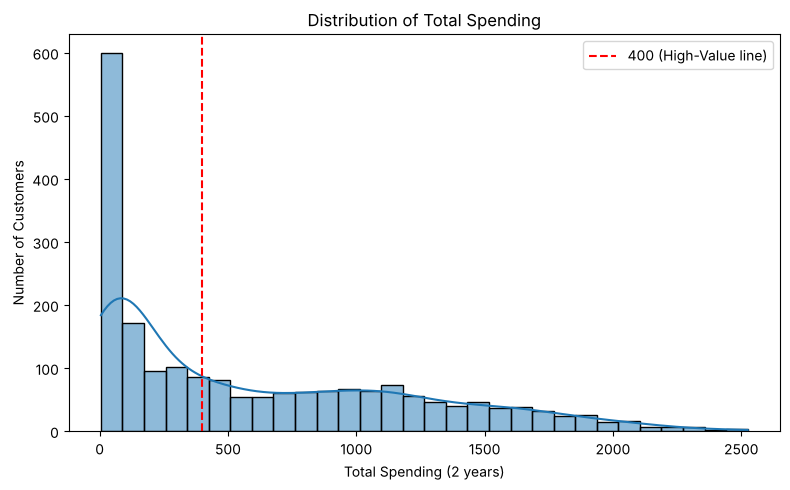

Mean  : 607.8
Median: 397.0


In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["total_spending"], bins=30, kde=True)
plt.axvline(400, color="red", linestyle="--", label="400 (High-Value line)")
plt.title("Distribution of Total Spending")
plt.xlabel("Total Spending (2 years)")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean  :", round(df["total_spending"].mean(), 1))
print("Median:", df["total_spending"].median())

**What it explains:** The chart is **right-skewed** – many customers spend a little and a few spend a lot. That is why the mean (608) is much higher than the median (397).

## Histogram – Income

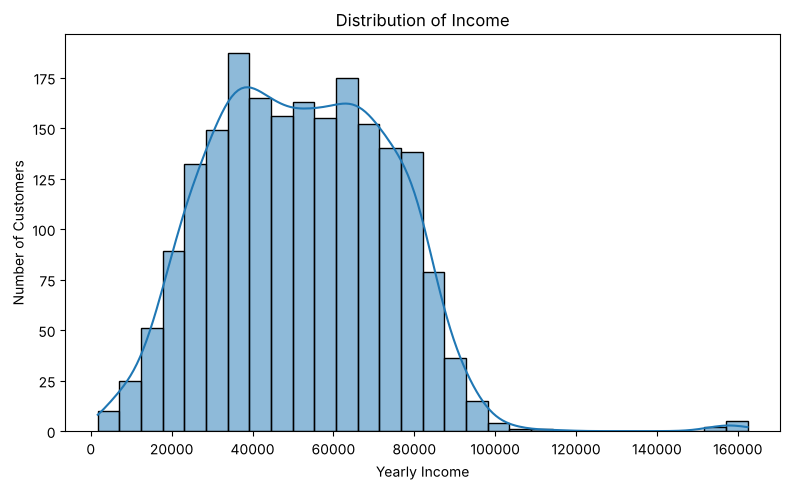

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(df["income"], bins=30, kde=True)
plt.title("Distribution of Income")
plt.xlabel("Yearly Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**What it explains:** After removing the outlier, income looks like a bell shape around 50,000.

## Histogram – Age

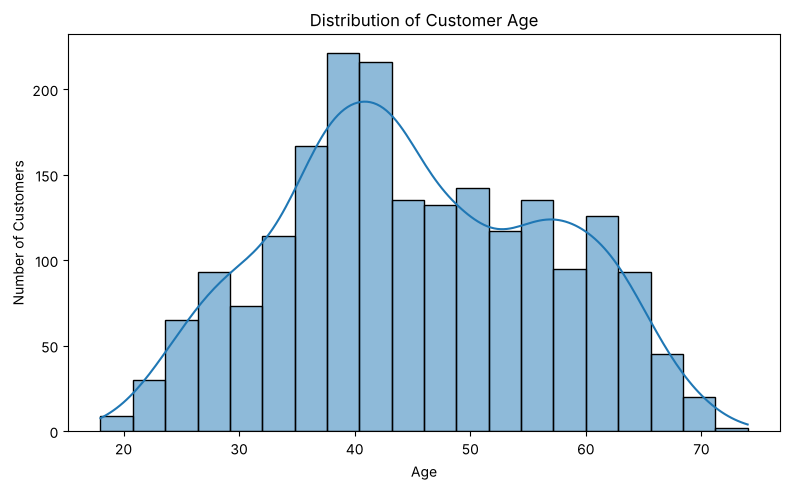

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(df["age"], bins=20, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**What it explains:** Most customers are between 35 and 60 years old.

## Scatter Plot – Income vs Total Spending

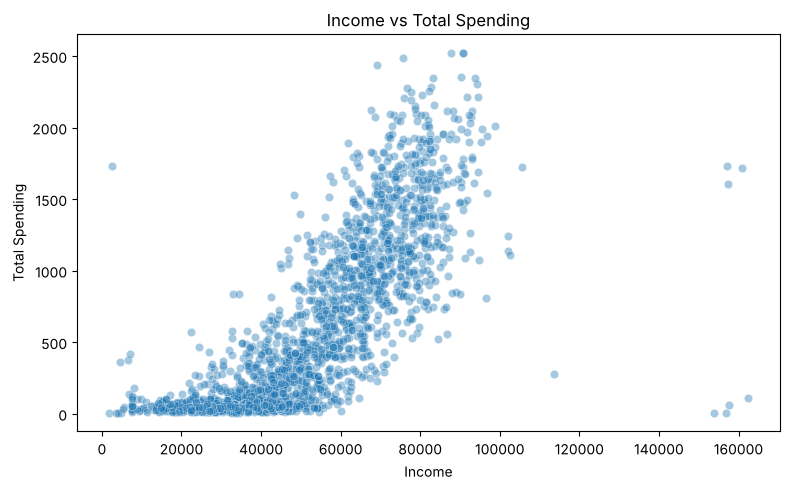

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="income", y="total_spending", alpha=0.4)
plt.title("Income vs Total Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

**What it explains:** Higher income → higher spending. This is the **strongest** relationship in the data. The pattern also curves (spending grows fast after about 60,000), so a straight line will not fit it perfectly.

## Bar Chart – Spending by Number of Kids

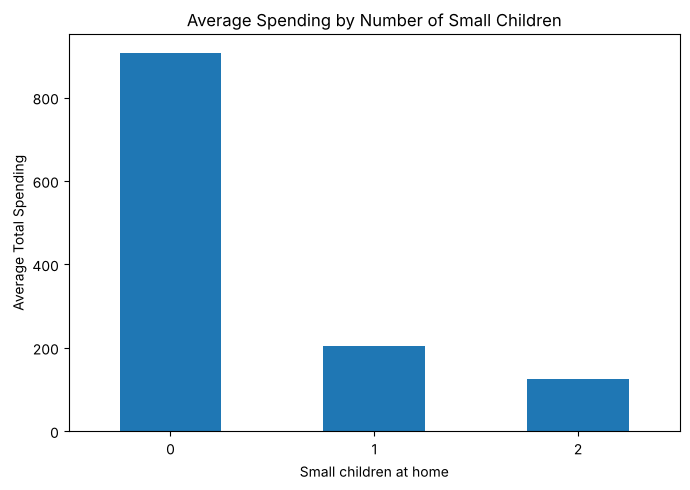

kids
0    906.0
1    205.0
2    125.0
Name: total_spending, dtype: float64


In [12]:
average = df.groupby("kids")["total_spending"].mean()

plt.figure(figsize=(7, 5))
average.plot(kind="bar")
plt.title("Average Spending by Number of Small Children")
plt.xlabel("Small children at home")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(average.round(0))

**What it explains:** Customers with **no small children spend about 906**, but with one child it drops to about 205. Kids at home is the second most important factor.

## Bar Chart – Spending by Education

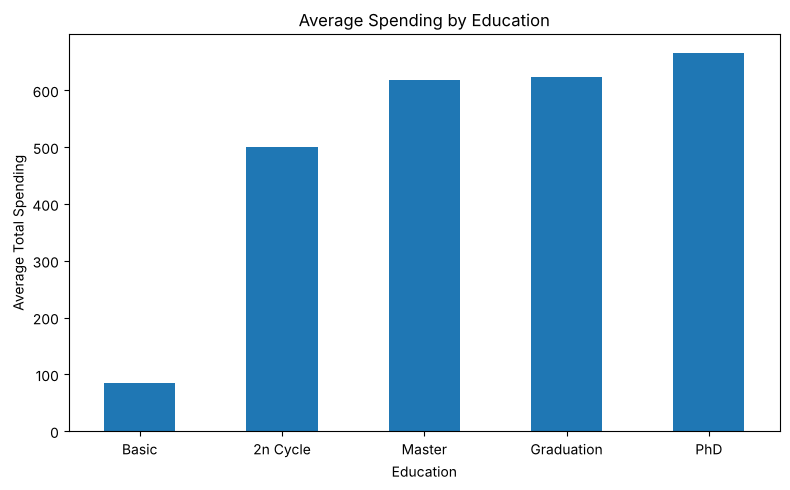

In [13]:
average = df.groupby("education")["total_spending"].mean().sort_values()

plt.figure(figsize=(8, 5))
average.plot(kind="bar")
plt.title("Average Spending by Education")
plt.xlabel("Education")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**What it explains:** Customers with **Basic** education spend much less (about 84). The other levels are close to each other (500–665).

## Box Plot – Spending by Marital Status

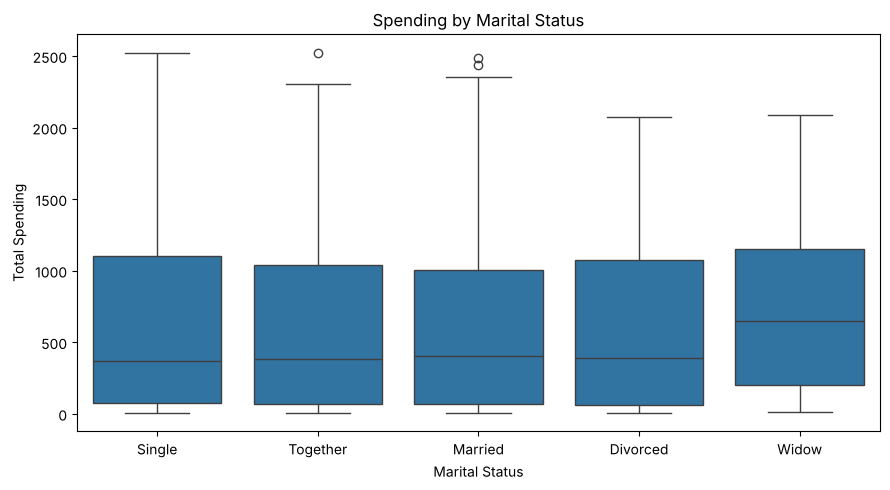

In [14]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="marital_status", y="total_spending")
plt.title("Spending by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

**What it explains:** The boxes look similar, so marital status has only a small effect on spending.

## Scatter Plot – Website Visits vs Spending

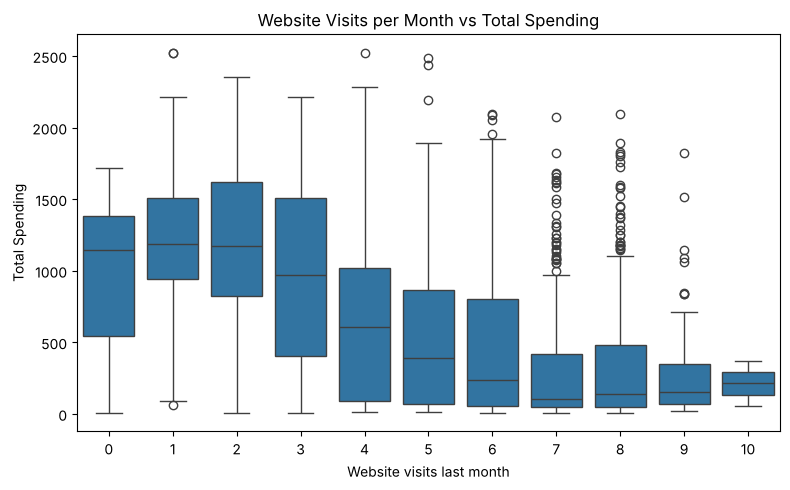

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[df["web_visits"] <= 10], x="web_visits", y="total_spending")
plt.title("Website Visits per Month vs Total Spending")
plt.xlabel("Website visits last month")
plt.ylabel("Total Spending")
plt.tight_layout()
plt.show()

**What it explains:** Customers who visit the website **more** often actually spend **less**. They may be browsing for deals rather than buying.

## Correlation Heatmap

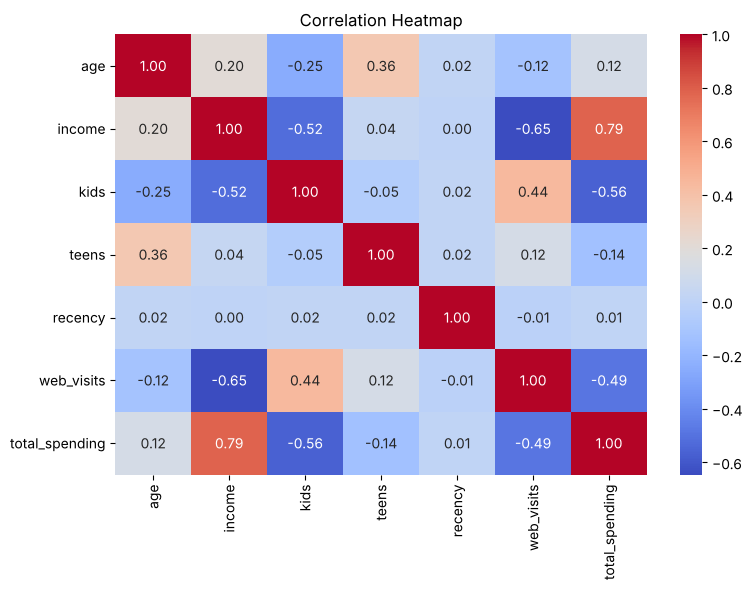

In [16]:
numbers = df[["age", "income", "kids", "teens", "recency", "web_visits", "total_spending"]]

plt.figure(figsize=(8, 6))
sns.heatmap(numbers.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**What it explains:** Correlation goes from -1 to +1.
- Income → **+0.79** with spending (strong)
- Kids → **-0.56** (more small children, less spending)
- Web visits → **-0.49**
- Age, teens, recency → weak

## Class Balance for Classification

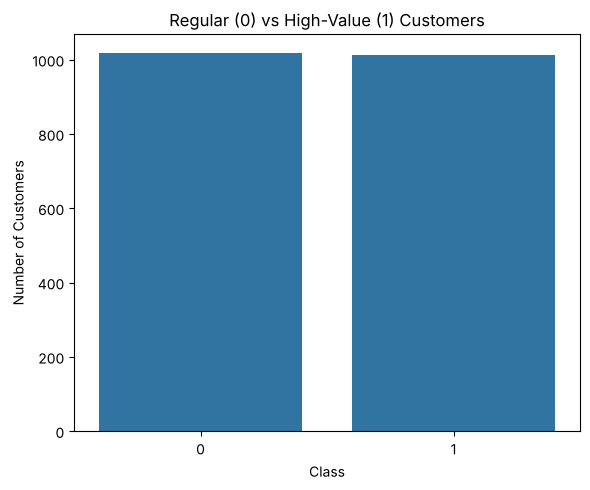

high_value
0    1017
1    1013
Name: count, dtype: int64


In [17]:
df["high_value"] = (df["total_spending"] >= 400).astype(int)

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="high_value")
plt.title("Regular (0) vs High-Value (1) Customers")
plt.xlabel("Class")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print(df["high_value"].value_counts())

**What it explains:** The 400 line splits customers into two almost equal groups (1,013 High-Value and 1,017 Regular), so accuracy is a fair way to compare models.

## Key Findings
1. **Income** is the strongest factor for spending.
2. Customers with **small children** and those who **visit the website often** spend less.
3. Education matters only at the **Basic** level; marital status and recency matter very little.
4. The raw data had missing incomes, repeated customers, impossible ages and odd categories – all fixed before modelling.